# meltpool series and data collection

here want to do a series of meltpool simulations and grab the vectors and other things.

In [2]:
import os
import pyPenred

## step 1: convert all .stls to geos with detector block

In [3]:
from concurrent.futures import ProcessPoolExecutor
from functools import partial
from pathlib import Path

from mesh2geo import mesh_to_geo

K = 1e4          # length scale for penRed's triangle tolerance, same as the example notebook
TOP_UM = 160.0   # common z = 0 for every frame (mesh frame, um); the series peaks at 156.5 um

folder = Path(r"E:\Code\EPBF_Twin\testing\meltpoolv2\stls")
geo_folder = folder.parent / "geos"
geo_folder.mkdir(exist_ok=True)

meshes = sorted(folder.glob("*.stl"))
geos = [geo_folder / m.with_suffix(".geo").name for m in meshes]

# Convert only frames without a .geo yet. Delete the geos folder if you change K or TOP_UM.
todo = [(m, g) for m, g in zip(meshes, geos) if not g.exists()]
print(f"{len(geos) - len(todo)} of {len(geos)} .geo files already exist, {len(todo)} to convert")
if todo:
    convert = partial(mesh_to_geo, units="m", scale=K, top_um=TOP_UM, verbose=False)
    todo_meshes, todo_geos = zip(*todo)
    with ProcessPoolExecutor(max_workers=16) as pool:
        for i, _ in enumerate(pool.map(convert, todo_meshes, todo_geos), 1):
            print(f"\r{i}/{len(todo)} frames converted", end="")

# penRed "geometry" config section for each frame, in time order (the same dict mesh_to_geo returns)
geometry_time = [{"type": "MESH_BODY", "input-file": str(g), "kdet": {"bse_detector": 1},
                  "dsmax": {"meltpool": 1e-4 * K}} for g in geos]

            


250 of 250 .geo files already exist, 0 to convert


## step 2: check the geos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mesh2geo import read_geo

# Time of each frame in ms, with the first block at 0
pool = pd.read_csv(folder / "c_Ti64_melt_powder_pool.csv")
t_ms = dict(zip(pool["block_file"].map(lambda s: Path(s).stem), pool["time_ms"] - pool["time_ms"].iloc[0]))


def draw_geo(ax, path, scale=1e4, elev=30, azim=-60, limits=None):
    """Draw a mesh2geo .geo onto a 3D axis: shaded melt pool, BSE slab and time stamp, in um.
    Returns the axis limits, so later frames can reuse them and the camera stays still."""
    bodies = read_geo(path, scale=scale)
    v, f = bodies["meltpool"]
    tri = v[f][:, ::-1] * [1e4, 1e4, -1e4]  # um, height = -z; reversed so the shading sees outward normals
    lo, hi = bodies["bse_detector"][0].min(axis=0) * 1e4, bodies["bse_detector"][0].max(axis=0) * 1e4
    h = -hi[2]                               # lower face of the slab
    slab = [[(lo[0], lo[1], h), (hi[0], lo[1], h), (hi[0], hi[1], h), (lo[0], hi[1], h)]]
    if limits is None:
        pts = tri.reshape(-1, 3)
        limits = np.c_[pts.min(axis=0), np.r_[pts[:, :2].max(axis=0), h]]  # rows x, y, z: (low, high)

    ax.clear()
    ax.add_collection3d(Poly3DCollection(tri, facecolors="#c87f4f", edgecolors="#c87f4f", linewidths=0.3,
                                         shade=True, lightsource=LightSource(azdeg=-60, altdeg=40)))
    ax.add_collection3d(Poly3DCollection(slab, facecolor="#b8c4cc", alpha=0.3, edgecolor="#3a3a38", linewidth=0.6))
    ax.set(xlim=limits[0], ylim=limits[1], zlim=limits[2])
    ax.set_box_aspect(limits[:, 1] - limits[:, 0])
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    name = Path(path).stem
    ax.set_title(f"{name}    t = {t_ms[name]:.3f} ms", loc="left")
    return limits


def view_geo(path, **kwargs):
    """Show one frame."""
    fig = plt.figure(figsize=(9, 7), facecolor="white")
    draw_geo(fig.add_subplot(projection="3d", computed_zorder=False), path, **kwargs)
    plt.show()




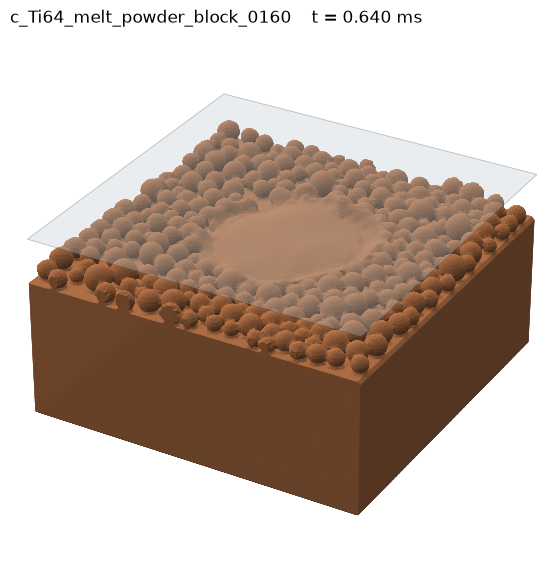

In [5]:
view_geo(geos[160])

In [6]:
from PIL import Image

STEP = 5   # every 5th frame (~20 us apart, 50 frames); 1 for all 250
frames_dir = folder.parent / "frames"
frames_dir.mkdir(exist_ok=True)

fig = plt.figure(figsize=(9, 7), facecolor="white")
ax = fig.add_subplot(projection="3d", computed_zorder=False)
limits, pngs = None, []
for geo in geos[::STEP]:
    limits = draw_geo(ax, geo, limits=limits)   # first frame sets the limits, the rest reuse them
    pngs.append(frames_dir / f"{Path(geo).stem}.png")
    fig.savefig(pngs[-1], dpi=100)
    print(f"\r{len(pngs)} frames drawn", end="")
plt.close(fig)

images = [Image.open(p) for p in pngs]
images[0].save(folder.parent / "meltpool_series.gif", save_all=True, append_images=images[1:],
               duration=100, loop=0)   # 100 ms per frame on screen, loops forever


50 frames drawn

# step 3: do bse simulation to find BSE

In [7]:
# setup our config.in file
import os
import subprocess
import sys

import numpy as np
import pandas as pd
import pyPenred

# Beam: the 727 W, 160 us spot from the time-series CSV, ~160 mm below the gun pivot
GUN_MM = 160.0
X_MM, Y_MM = 27.58850098, -11.78100586                          # spot position relative to the gun axis
theta = np.degrees(np.arctan(np.hypot(X_MM, Y_MM) / GUN_MM))    # 10.6 deg from vertical
phi = np.degrees(np.arctan2(Y_MM, X_MM)) % 360                  # direction the beam leans

# Source just below the BSE slab, on the gun-to-spot line through the mesh centre at mesh z = 0
SOURCE_Z_UM = -1.0                                              # penRed frame (z = 0 is TOP_UM in the mesh)
drop = TOP_UM - SOURCE_Z_UM                                     # um from the source down to mesh z = 0
source_um = (-drop * X_MM / GUN_MM, -drop * Y_MM / GUN_MM, SOURCE_Z_UM)

NHIST = 1e5
LAST_FRAME = 40
UM = 1e-4
HERE = folder.parent                                            # meltpoolv2
RUNS, BSE_DIR = HERE / "runs", HERE / "bse"
RUNS.mkdir(exist_ok=True)
BSE_DIR.mkdir(exist_ok=True)

# Materials at density / K, made once and shared by every run
air = [(6, 0.000124), (7, 0.755268), (8, 0.231781), (18, 0.012827)]
pyPenred.simulation.materials.create("Ti64", 4.43 / K, [(22, 0.90), (13, 0.06), (23, 0.04)], str(RUNS / "Ti64_scaled.mat"))
pyPenred.simulation.materials.create("nearvac", 1e-10 / K, air, str(RUNS / "nearvac_scaled.mat"))

# One config for every frame; only the geometry changes
config = pyPenred.readConfigFile(r"E:\Code\EPBF_Twin\testing\particlev2\config.in")
config["materials"]["Ti64"] = config["materials"].pop("cu")
config["materials"]["Ti64"]["filename"] = str(RUNS / "Ti64_scaled.mat")
config["materials"]["nearvac"]["filename"] = str(RUNS / "nearvac_scaled.mat")
source = config["sources"]["generic"]["source1"]
source["nhist"] = NHIST
source["direction"].update(theta=theta, phi=phi, alpha=0.0)
for axis, value in zip("xyz", source_um):
    source["spatial"]["position"][axis] = value * UM * K
config["tallies"] = {"psf": config["tallies"]["psf"],              # every BSE entering the slab
                     "track": {"type": "TRACK", "nhists": 1}}      # 1 full track per thread, for the animation
source["energy"]["energy"] = 60e3          # 60 kV beam, in eV
config["tallies"]["psf"]["emax"] = 60.5e3  # the PSF only records electrons up to emax

config["simulation"]["threads"] = os.cpu_count()

COLUMNS = ["DHIST", "KPAR", "E", "X", "Y", "Z", "U", "V", "W", "WGHT", "PAGE", "ILB1", "ILB2", "ILB3", "ILB4", "ILB5"]


In [8]:
from concurrent.futures import ThreadPoolExecutor

PARALLEL = 16                              # frames running at once
THREADS = os.cpu_count() // PARALLEL       # penRed threads per frame (4 on this machine)
config["simulation"]["threads"] = THREADS
config["tallies"]["track"]["nhists"] = PARALLEL   # nhists is per thread: keeps ~64 tracked primaries per frame

# Write each frame's config first (fast); the pool only runs penRed and reads the results
todo = []
for geo, geometry in list(zip(geos, geometry_time))[:LAST_FRAME + 1]:
    run = RUNS / Path(geo).stem
    if (BSE_DIR / f"{run.name}.csv").exists():   # already done, so you can stop and rerun this cell
        continue
    run.mkdir(exist_ok=True)
    config["geometry"] = geometry
    pyPenred.writeConfigFile(str(run / "run.in"), config)
    todo.append(run)


def simulate(run):
    """Run one frame in its own penRed process, then save its BSE as a CSV (mesh frame, um and keV)."""
    subprocess.run([sys.executable, "-c", "import pyPenred; pyPenred.runFromFile('run.in')"],
                   cwd=run, stdout=subprocess.DEVNULL, check=True)
    pyPenred.psf.psf2ascii(str(run / "psf-merged.dat"), str(run / "psf-electrons.txt"))
    psf = pd.read_csv(run / "psf-electrons.txt", sep=r"\s+", comment="#", header=None, names=COLUMNS)
    bse = psf[(psf["KPAR"] == 0) & (psf["W"] < 0)]
    pd.DataFrame({
        "E_keV": bse["E"] / 1e3,
        "x_um": bse["X"] / K / UM, "y_um": bse["Y"] / K / UM, "z_um": TOP_UM - bse["Z"] / K / UM,
        "u": bse["U"], "v": bse["V"], "w": -bse["W"], "weight": bse["WGHT"],
    }).to_csv(BSE_DIR / f"{run.name}.csv", index=False)
    (run / "psf-merged.dat").unlink()        # the CSV keeps what's needed
    return run.name, len(bse)


import time
from concurrent.futures import FIRST_COMPLETED, wait

start = time.time()
with ThreadPoolExecutor(PARALLEL) as pool:
    pending = {pool.submit(simulate, run) for run in todo}
    done = 0
    while pending:
        finished, pending = wait(pending, timeout=1, return_when=FIRST_COMPLETED)
        for future in finished:
            name, n = future.result()
            done += 1
            print(f"\r{name}  t = {1000 * t_ms[name]:6.1f} us  BSE per primary {n / NHIST:.4f}".ljust(80))
        elapsed = time.time() - start
        left = f"~{elapsed / done * (len(todo) - done) / 60:.0f} min left" if done else "first frames running"
        print(f"\r{done}/{len(todo)} frames done, {elapsed / 60:.1f} min elapsed, {left}", end="")



c_Ti64_melt_powder_block_0008  t =   32.1 us  BSE per primary 0.2298           
c_Ti64_melt_powder_block_0015  t =   59.9 us  BSE per primary 0.1707           
c_Ti64_melt_powder_block_0009  t =   36.0 us  BSE per primary 0.2169           
c_Ti64_melt_powder_block_0011  t =   44.0 us  BSE per primary 0.2364           
c_Ti64_melt_powder_block_0010  t =   39.9 us  BSE per primary 0.2076           
c_Ti64_melt_powder_block_0017  t =   68.1 us  BSE per primary 0.1702           
c_Ti64_melt_powder_block_0002  t =    7.9 us  BSE per primary 0.3176           
c_Ti64_melt_powder_block_0005  t =   20.1 us  BSE per primary 0.3051           
c_Ti64_melt_powder_block_0014  t =   56.0 us  BSE per primary 0.1845           
c_Ti64_melt_powder_block_0004  t =   15.9 us  BSE per primary 0.2365           
c_Ti64_melt_powder_block_0018  t =   72.1 us  BSE per primary 0.2000           
c_Ti64_melt_powder_block_0016  t =   64.0 us  BSE per primary 0.1877           
c_Ti64_melt_powder_block_0001  t =    4.

In [9]:
from PIL import Image


def draw_tracks(ax, run):
    """Overlay the primary tracks saved in a run folder: blue if the electron reached the BSE slab."""
    for path in sorted(run.glob("track-th*-electron-tracks.dat")):
        for block in path.read_text().split("\n\n\n"):
            rows = [l.split() for l in block.splitlines() if l.strip() and not l.startswith("#")]
            if rows and rows[0][11] == "1":   # primaries only
                t = np.array(rows, float)
                reached = ((t[:, 8] == 1) & (t[:, 6] < 0)).any()
                ax.plot(t[:, 1] / K / UM, t[:, 2] / K / UM, -t[:, 3] / K / UM, zorder=3,
                        color="#2a78d6" if reached else "#77766f", lw=1.0 if reached else 0.4)


STEP = 1
frames_dir = HERE / "frames_bse"
frames_dir.mkdir(exist_ok=True)
fig = plt.figure(figsize=(9, 7), facecolor="white")
ax = fig.add_subplot(projection="3d", computed_zorder=False)
limits, pngs = None, []
for geo in geos[:LAST_FRAME + 1:STEP]:
    limits = draw_geo(ax, geo, limits=limits)
    draw_tracks(ax, RUNS / Path(geo).stem)
    pngs.append(frames_dir / f"{Path(geo).stem}.png")
    fig.savefig(pngs[-1], dpi=100)
    print(f"\r{len(pngs)} frames drawn", end="")
plt.close(fig)

images = [Image.open(p) for p in pngs]
images[0].save(HERE / "bse_series.gif", save_all=True, append_images=images[1:], duration=100, loop=0)


41 frames drawn

# step 4: trace electrons back to detectors

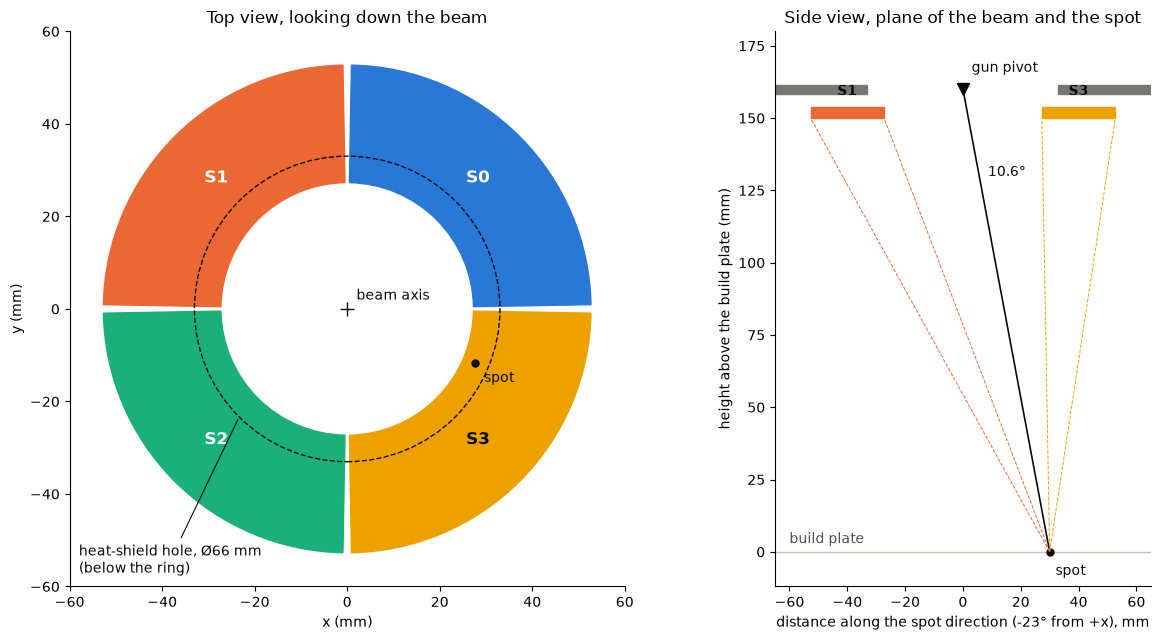

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Wedge

# Detector geometry in mm, build-plate frame: origin under the gun, z up from the plate
GUN_MM = 160.0                         # gun pivot above the build plate
DET_Z_MM = 160.0                       # detector face height above the build plate
DET_R_MM = 40.0                        # ring centre-line radius from the beam axis
DET_WIDTH_MM = 25.4                    # radial width, about an inch
DET_GAP_DEG = 2.0                      # gap between segments (assumed)
DET_ROT_DEG = 0.0                      # S0 starts here, counter-clockwise from +x (assumed)
SPOT_MM = (27.58850098, -11.78100586)  # 727 W, 160 us spot
SHIELD_HOLE_MM = 2.6 * 25.4            # heat-shield hole diameter (66.0 mm), centred on the beam axis
SHIELD_Z_MM = 150.0                     # heat-shield height above the plate: PLACEHOLDER, set the real value

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # S0..S3
r_in, r_out = DET_R_MM - DET_WIDTH_MM / 2, DET_R_MM + DET_WIDTH_MM / 2


def segment(phi_deg):
    """Detector segment (0-3) above azimuth phi, counter-clockwise from +x."""
    return int(((phi_deg - DET_ROT_DEG) % 360) // 90)


fig, (top, side) = plt.subplots(1, 2, figsize=(13, 6.5))

# Top view, looking down the beam axis
for k in range(4):
    a0 = DET_ROT_DEG + 90 * k + DET_GAP_DEG / 2
    top.add_patch(Wedge((0, 0), r_out, a0, a0 + 90 - DET_GAP_DEG, width=DET_WIDTH_MM, color=COLORS[k]))
    mid = np.radians(a0 + 45 - DET_GAP_DEG / 2)
    top.text(DET_R_MM * np.cos(mid), DET_R_MM * np.sin(mid), f"S{k}", ha="center", va="center",
             color="#0b0b0b" if k == 3 else "white", fontsize=12, fontweight="bold")
top.add_patch(Circle((0, 0), SHIELD_HOLE_MM / 2, fill=False, ec="#0b0b0b", ls="--", lw=1, zorder=3))  # hidden below the ring
h = np.radians(225)
top.annotate(f"heat-shield hole, Ø{SHIELD_HOLE_MM:.0f} mm\n(below the ring)", (SHIELD_HOLE_MM / 2 * np.cos(h), SHIELD_HOLE_MM / 2 * np.sin(h)),
             (-58, -57), color="#0b0b0b", arrowprops=dict(arrowstyle="-", color="#0b0b0b", lw=0.8))
top.plot(0, 0, "+", color="#0b0b0b", ms=10)
top.text(2, 2, "beam axis", color="#0b0b0b")
top.plot(*SPOT_MM, "o", color="#0b0b0b", ms=5)
top.text(SPOT_MM[0] + 2, SPOT_MM[1] - 4, "spot", color="#0b0b0b")
top.set(xlim=(-60, 60), ylim=(-60, 60), aspect="equal", xlabel="x (mm)", ylabel="y (mm)",
        title="Top view, looking down the beam")

# Side view in the vertical plane through the beam axis and the spot
r_spot = np.hypot(*SPOT_MM)
phi = np.degrees(np.arctan2(SPOT_MM[1], SPOT_MM[0]))
side.axhline(0, color="#c3c2b7", lw=1)
side.text(-60, 3, "build plate", color="#52514e")
side.plot([0, r_spot], [GUN_MM, 0], color="#0b0b0b", lw=1.2)
side.plot(0, GUN_MM, "v", color="#0b0b0b", ms=8)
side.text(3, GUN_MM + 6, "gun pivot", color="#0b0b0b")
side.text(r_spot * (1 - 130 / GUN_MM) + 3, 130, f"{np.degrees(np.arctan(r_spot / GUN_MM)):.1f}°", color="#0b0b0b")
side.plot(r_spot, 0, "o", color="#0b0b0b", ms=5)
side.text(r_spot + 2, -8, "spot", color="#0b0b0b")
for sign in (1, -1):
    k = segment(phi if sign > 0 else phi + 180)  # which segment this side of the plane cuts
    x0 = r_in if sign > 0 else -r_out
    side.add_patch(Rectangle((x0, DET_Z_MM), DET_WIDTH_MM, 4, color=COLORS[k]))
    side.text(sign * DET_R_MM, DET_Z_MM + 8, f"S{k}", ha="center", color="#0b0b0b", fontweight="bold")
    for edge in (r_in, r_out):  # lines of sight from the spot to the segment's edges
        side.plot([r_spot, sign * edge], [0, DET_Z_MM], color=COLORS[k], lw=0.7, ls="--")
for x0 in (SHIELD_HOLE_MM / 2, -65):  # heat shield either side of its hole
    side.add_patch(Rectangle((x0, SHIELD_Z_MM - 1.5), 65 - SHIELD_HOLE_MM / 2, 3, color="#77766f"))
side.set(xlim=(-65, 65), ylim=(-12, 180), aspect="equal",
         xlabel=f"distance along the spot direction ({phi:.0f}° from +x), mm",
         ylabel="height above the build plate (mm)", title="Side view, plane of the beam and the spot")

for ax in (top, side):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

